In [1]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# --- 1. Assumptions ---
# Let's assume our model can handle sentences up to 100 words long.
max_sequence_length = 100
# Let's assume our word embeddings have a dimension of 128.
embedding_dimension = 128

# --- 2. Generate the Positional Encoding Matrix (No Function) ---
print(f"Generating Positional Encoding matrix for a sequence length of {max_sequence_length} and embedding dimension of {embedding_dimension}...")


Generating Positional Encoding matrix for a sequence length of 100 and embedding dimension of 128...


In [4]:

# Initialize a matrix of zeros for the positional encodings
pe_matrix = np.zeros((max_sequence_length, embedding_dimension))

# Create a column vector representing the positions [0, 1, ..., max_seq_len-1]
position = np.arange(0, max_sequence_length, dtype=np.float32).reshape(-1, 1)
print(position.T)

[[ 0.  1.  2.  3.  4.  5.  6.  7.  8.  9. 10. 11. 12. 13. 14. 15. 16. 17.
  18. 19. 20. 21. 22. 23. 24. 25. 26. 27. 28. 29. 30. 31. 32. 33. 34. 35.
  36. 37. 38. 39. 40. 41. 42. 43. 44. 45. 46. 47. 48. 49. 50. 51. 52. 53.
  54. 55. 56. 57. 58. 59. 60. 61. 62. 63. 64. 65. 66. 67. 68. 69. 70. 71.
  72. 73. 74. 75. 76. 77. 78. 79. 80. 81. 82. 83. 84. 85. 86. 87. 88. 89.
  90. 91. 92. 93. 94. 95. 96. 97. 98. 99.]]


In [6]:

# Create the division term for the sine and cosine functions.
# This term creates different frequencies for each dimension.
# Formula: 1 / (10000^(2i / d_model))
div_term = np.exp(np.arange(0, embedding_dimension, 2, dtype=np.float32) * -(np.log(10000.0) / embedding_dimension))

# Apply sine to even indices in the d_model dimension
pe_matrix[:, 0::2] = np.sin(position * div_term)

# Apply cosine to odd indices in the d_model dimension
pe_matrix[:, 1::2] = np.cos(position * div_term)

print("Matrix generated successfully.")
print(pe_matrix.T)

Matrix generated successfully.
[[ 0.00000000e+00  8.41470985e-01  9.09297427e-01 ...  3.79607739e-01
  -5.73381872e-01 -9.99206834e-01]
 [ 1.00000000e+00  5.40302306e-01 -4.16146837e-01 ... -9.25147537e-01
  -8.19288245e-01  3.98208804e-02]
 [ 0.00000000e+00  7.61720408e-01  9.87046251e-01 ...  7.34182803e-01
  -4.14901294e-02 -7.87946200e-01]
 ...
 [ 1.00000000e+00  9.99999991e-01  9.99999964e-01 ...  9.99916342e-01
   9.99914608e-01  9.99912857e-01]
 [ 0.00000000e+00  1.15478198e-04  2.30956395e-04 ...  1.12011510e-02
   1.13166219e-02  1.14320926e-02]
 [ 1.00000000e+00  9.99999993e-01  9.99999973e-01 ...  9.99937265e-01
   9.99935965e-01  9.99934651e-01]]


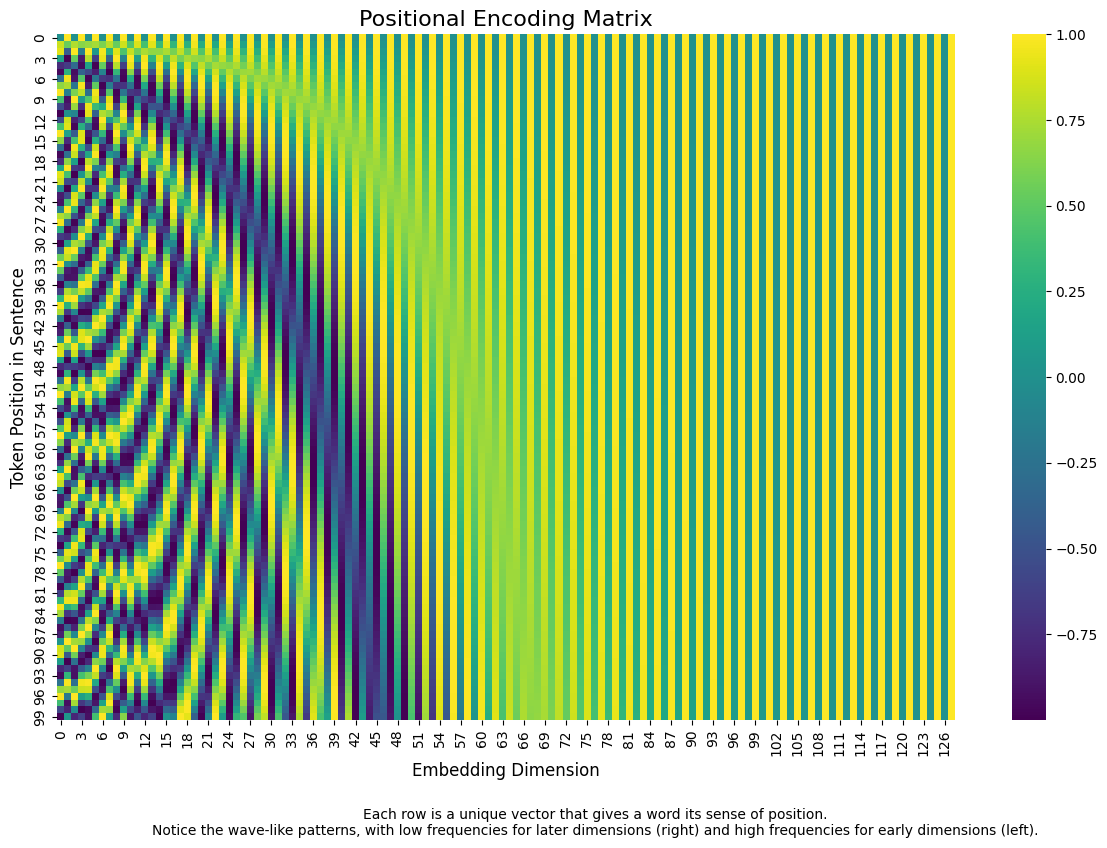

In [7]:

# --- 3. Visualize the Positional Encoding Matrix ---
plt.figure(figsize=(12, 8))
sns.heatmap(pe_matrix, cmap="viridis", cbar=True)
plt.title("Positional Encoding Matrix", fontsize=16)
plt.xlabel("Embedding Dimension", fontsize=12)
plt.ylabel("Token Position in Sentence", fontsize=12)
plt.figtext(0.5, -0.05,
            "Each row is a unique vector that gives a word its sense of position.\nNotice the wave-like patterns, with low frequencies for later dimensions (right) and high frequencies for early dimensions (left).",
            ha="center", fontsize=10)
plt.tight_layout()
plt.show()



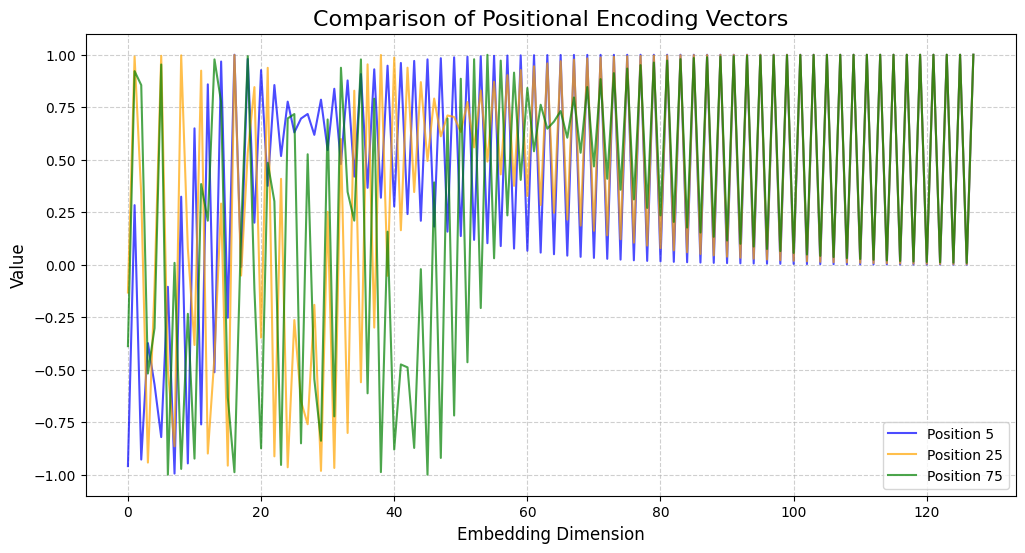

In [8]:

# --- 4. Visualize Specific Position Vectors ---
# Let's compare the encoding vectors for two different positions to see how unique they are.
pos_5 = pe_matrix[5, :]
pos_25 = pe_matrix[25, :]
pos_75 = pe_matrix[75, :]

plt.figure(figsize=(12, 6))
plt.plot(pos_5, label=f"Position 5", color='blue', alpha=0.7)
plt.plot(pos_25, label=f"Position 25", color='orange', alpha=0.7)
plt.plot(pos_75, label=f"Position 75", color='green', alpha=0.7)
plt.title("Comparison of Positional Encoding Vectors", fontsize=16)
plt.xlabel("Embedding Dimension", fontsize=12)
plt.ylabel("Value", fontsize=12)
plt.legend()
plt.grid(True, linestyle='--', alpha=0.6)
plt.show()

